# 03 — Modeling
Train Decision Tree, Random Forest, XGBoost and Logistic Regression with Optuna hyperparameter tuning and probability-threshold sweeps.

In [1]:
# Kernel bootstrap — run first
import sys, os
def _find_root():
    for base in [os.getcwd(), os.path.abspath(".."), os.path.abspath(".")]:
        for cand in [base, os.path.dirname(base)]:
            if os.path.isfile(os.path.join(cand, "requirements.txt")) and os.path.isdir(os.path.join(cand, "src")):
                return cand
    return os.path.abspath("..")
_project_root = _find_root()
if _project_root not in sys.path: sys.path.insert(0, _project_root)
os.chdir(_project_root)
from src.bootstrap import ensure
ensure({'pandas_datareader':'pandas-datareader','ta':'ta','yaml':'pyyaml',
        'yfinance':'yfinance','xgboost':'xgboost','optuna':'optuna'})
print("bootstrap OK")


bootstrap OK


In [2]:
%load_ext autoreload
%autoreload 2
import pandas as pd, numpy as np
from pathlib import Path
parquet = Path('data/processed/df_combined.parquet')
if not parquet.exists():
    print('df_combined.parquet not found — building features now...')
    for needed, fn in [('data/raw/yf_all.parquet', 'src.data.download_yf'),
                       ('data/raw/macro_fred.parquet', 'src.data.download_fred')]:
        if not Path(needed).exists():
            mod = __import__(fn, fromlist=['download'])
            mod.download()
    if not Path('data/raw/news_headlines.parquet').exists():
        from src.data.download_dgap import download as dl_news
        try: dl_news()
        except Exception as e: print(f'news skipped: {e}')
    from src.features.build_features import build_dataset
    df, _ = build_dataset()
else:
    df = pd.read_parquet(parquet)
print('shape:', df.shape)


shape: (994718, 178)


In [3]:
%load_ext autoreload
%autoreload 2
from src.models.train import train
models, features, results = train()
results.head(15)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


08:06:33 [INFO] eu-midcap-echo: training with 159 features
08:06:37 [INFO] eu-midcap-echo: splits: train=669708, val=162272, test=162738
08:32:01 [INFO] eu-midcap-echo: saved bundle with 159 features, 4 models
08:32:01 [INFO] eu-midcap-echo: best models:
      model  threshold      n  precision  mean_proba
   xgb_best       0.70   7714   0.583744    0.354331
    rf_best       0.60  11367   0.581772    0.499892
   xgb_best       0.65  12833   0.570404    0.353425
   xgb_best       0.60  19194   0.566375    0.352299
   xgb_best       0.55  26775   0.561494    0.350957
lr_balanced       0.65  76829   0.556431    0.570439
   xgb_best       0.50  35528   0.555506    0.349407
lr_balanced       0.60 117274   0.546148    0.561745


,model,threshold,n,precision,mean_proba
13,xgb_best,0.70,7714,0.583744,0.354331
7,rf_best,0.60,11367,0.581772,0.499892
12,xgb_best,0.65,12833,0.570404,0.353425
11,xgb_best,0.60,19194,0.566375,0.352299
10,xgb_best,0.55,26775,0.561494,0.350957
17,lr_balanced,0.65,76829,0.556431,0.570439
9,xgb_best,0.50,35528,0.555506,0.349407
16,lr_balanced,0.60,117274,0.546148,0.561745
18,lr_balanced,0.70,33996,0.541887,0.579647
15,lr_balanced,0.55,142590,0.537317,0.556303


In [6]:
# Best model/threshold combo (highest precision)
best = results.sort_values('precision', ascending=False).iloc[0]
print('Best model/threshold:')
print(best.to_dict())
print()
print('Top 10 combos:')
print(results.head(10).to_string(index=False))

Best model/threshold:
{'model': 'xgb_best', 'threshold': 0.7, 'n': 7714, 'precision': 0.583743842364532, 'mean_proba': 0.35433104634284973}

Top 10 combos:
      model  threshold      n  precision  mean_proba
   xgb_best       0.70   7714   0.583744    0.354331
    rf_best       0.60  11367   0.581772    0.499892
   xgb_best       0.65  12833   0.570404    0.353425
   xgb_best       0.60  19194   0.566375    0.352299
   xgb_best       0.55  26775   0.561494    0.350957
lr_balanced       0.65  76829   0.556431    0.570439
   xgb_best       0.50  35528   0.555506    0.349407
lr_balanced       0.60 117274   0.546148    0.561745
lr_balanced       0.70  33996   0.541887    0.579647
lr_balanced       0.55 142590   0.537317    0.556303


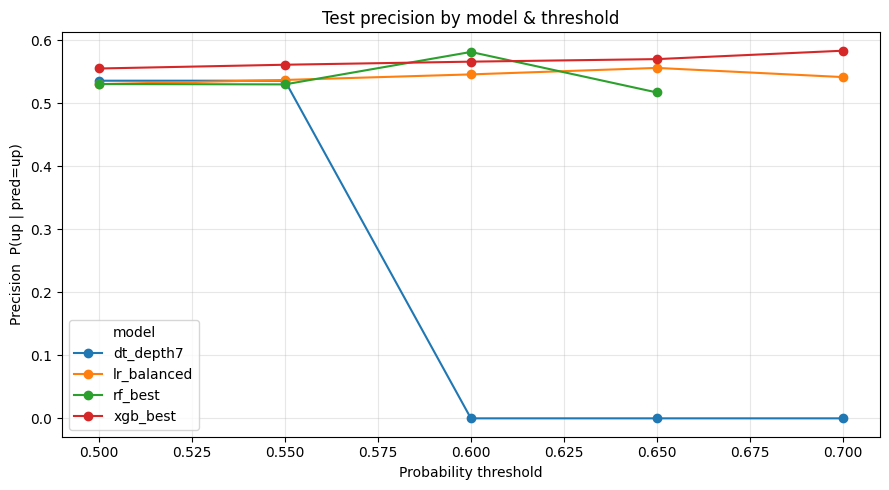

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
pivot = results.pivot_table(index='threshold', columns='model', values='precision')
ax = pivot.plot(marker='o', figsize=(9,5), title='Test precision by model & threshold')
ax.set_ylabel('Precision  P(up | pred=up)')
ax.set_xlabel('Probability threshold')
ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
